# Are there more road accidents on Friday the 13th? The notebook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/john-bruene/pointzerofive-data/blob/main/friday-the-13th/story_005_friday_13th.ipynb)

This notebook recomputes every statistic in
[Are there more road accidents on Friday the 13th?](https://pointzerofive.net/2026/10/friday-the-13th),
story #005 on *pointzerofive*, from the daily collision counts. Run it top to bottom
(`Runtime → Run all` in Colab). The bootstrap cell runs 18 × 10,000 replicates and takes under a minute.

**The question:** do more road collisions with injured people happen in Great Britain on a Friday
the 13th than on the Fridays a week before and after?

Every choice below was fixed in the pitch before the analysis
([pitch.md](https://github.com/john-bruene/pointzerofive-data/blob/main/friday-the-13th/pitch.md),
commit d260eb5). Each quoted number is printed and checked with `assert` against the published dataset
`data/friday-the-13th.json`.

Source: Department for Transport, Road Safety Data (STATS19). Contains public sector information
licensed under the Open Government Licence v3.0.

In [1]:
%pip install -q holidays==0.106

In [2]:
import io
import json
import math
import pathlib
import urllib.request

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE = "https://raw.githubusercontent.com/john-bruene/pointzerofive-data/main/friday-the-13th/"
REPO = pathlib.Path("..")


def fetch(rel_path: str) -> bytes:
    # next to the notebook (pointzerofive-data), in the website's repository, else downloaded
    name = rel_path.rsplit("/", 1)[-1]
    for local in (pathlib.Path(name), REPO / rel_path):
        if local.exists():
            return local.read_bytes()
    with urllib.request.urlopen(BASE + name) as response:
        return response.read()


def close(a, b, tol=0.051):
    assert math.isclose(a, b, abs_tol=tol), (a, b)


daily = pd.read_csv(io.BytesIO(fetch("notebooks/raw/stats19/daily_collisions.csv")), parse_dates=["date"])
daily.index = daily.date.dt.date
daily = daily.drop(columns="date")
raw_meta = json.loads(fetch("notebooks/raw/stats19/daily_collisions.meta.json"))
pub = json.loads(fetch("data/friday-the-13th.json"))
S, M = pub["summary"], pub["main"]
print(f"{len(daily):,} days, {daily.index.min()} to {daily.index.max()}, {daily['all'].sum():,} collisions")

17,167 days, 1979-01-01 to 2025-12-31, 9,116,617 collisions


## 1. The daily counts

`notebooks/friday13_pipeline.py` streams the STATS19 collision file (1979 to the latest published
year, about 9 million rows) and counts collisions per day: `all` (every collision with at least one
injured person), `ksi` (police severity fatal or serious) and `fatal`. Every day of the period has
at least one collision, so no day is missing.

In [3]:
assert len(pd.date_range(daily.index.min(), daily.index.max())) == len(daily) == S["days"]
assert int(daily["all"].sum()) == S["collisions"] == raw_meta["rows"] - raw_meta["undated"]
assert int(daily["ksi"].sum()) == S["ksi"] and int(daily["fatal"].sum()) == S["fatal"]
first, last = daily.index.min().year, daily.index.max().year
per_year = daily.groupby([d.year for d in daily.index])["all"].agg(["sum", "size"])
for year, key in [(first, "perDayFirstYear"), (last, "perDayLastYear")]:
    v = per_year.loc[year, "sum"] / per_year.loc[year, "size"]
    print(f"{year}: {v:.1f} collisions a day")
    close(v, S[key])
print(f"undated records left out: {raw_meta['undated']}")

1979: 698.5 collisions a day
2025: 278.2 collisions a day
undated records left out: 8


## 2. Fridays the 13th and bank holidays

Bank holidays in England and Wales come from the Python package `holidays` (version 0.106,
`UK(subdiv="ENG")`). Good Friday falls on the 13th three times in the period.

In [4]:
HOL = set(holidays.UK(subdiv="ENG", years=range(first, last + 1)))
f13 = [pd.Timestamp(y, m, 13).date() for y in range(first, last + 1) for m in range(1, 13)
       if pd.Timestamp(y, m, 13).weekday() == 4]
holiday13 = [d for d in f13 if d in HOL]
controls_on_holidays = sorted(d.replace(day=k) for d in f13 for k in (6, 20) if d.replace(day=k) in HOL)
print(f"{len(f13)} Fridays the 13th; on a bank holiday: {holiday13}")
print(f"comparison Fridays on a bank holiday: {controls_on_holidays}")
assert len(f13) == S["fridays13"]
assert [d.isoformat() for d in holiday13] == S["holiday13"]
assert [d.isoformat() for d in controls_on_holidays] == S["holidayControls"]

81 Fridays the 13th; on a bank holiday: [datetime.date(1979, 4, 13), datetime.date(1990, 4, 13), datetime.date(2001, 4, 13)]
comparison Fridays on a bank holiday: [datetime.date(1984, 4, 20), datetime.date(2007, 4, 6), datetime.date(2012, 4, 6)]


## 3. The first attempt: all other days of the month

Compare each Friday the 13th with the average of all other days of its month (bank holidays left
out). Then look at the weekdays: Friday is the day with the most collisions.

Friday the 13th: 627.6 a day; other days of the month: 525.7; +19.36 %
Mon    531.1
Tue    526.4
Wed    544.1
Thu    568.1
Fri    626.0
Sat    523.4
Sun    414.6
Fridays (not the 13th) against the average day, whole period: +18.1 %


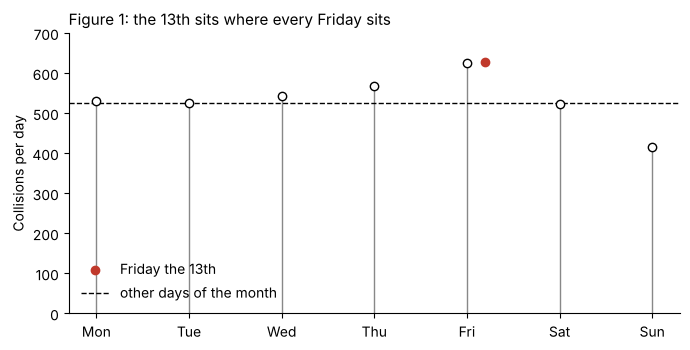

In [5]:
main13 = [d for d in f13 if d not in HOL]
naive_y = np.array([daily.loc[d, "all"] for d in main13], float)
naive_c = np.array([daily.loc[[d.replace(day=k) for k in range(1, pd.Timestamp(d).days_in_month + 1)
                               if k != 13 and d.replace(day=k) not in HOL], "all"].mean() for d in main13])
naive = 100 * (naive_y.sum() / naive_c.sum() - 1)
print(f"Friday the 13th: {naive_y.mean():.1f} a day; other days of the month: {naive_c.mean():.1f}; {naive:+.2f} %")
close(naive_y.mean(), M["naiveMean13"]); close(naive_c.mean(), M["naiveMeanComparison"])

months = {(d.year, d.month) for d in main13}
days = [d for d in daily.index if (d.year, d.month) in months and d not in HOL and d.day != 13]
wd = daily.loc[days, "all"].groupby([d.weekday() for d in days]).mean()
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
for i, row in enumerate(pub["weekdays"]):
    assert row["weekday"] == names[i]
    close(wd[i], row["mean"])
print(wd.rename(dict(enumerate(names))).round(1).to_string())

fridays = [d for d in daily.index if d.weekday() == 4 and d not in HOL and d.day != 13]
fva = 100 * (daily.loc[fridays, "all"].mean() / daily.loc[[d for d in daily.index if d not in HOL], "all"].mean() - 1)
print(f"Fridays (not the 13th) against the average day, whole period: {fva:+.1f} %")
close(fva, S["fridayVsAverage"], 0.006)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.vlines(range(7), 0, wd.values, color="#888888", lw=1)
ax.scatter(range(7), wd.values, facecolors="white", edgecolors="black", zorder=3)
ax.scatter([4.2], [naive_y.mean()], color="#c0392b", zorder=3, label="Friday the 13th")
ax.axhline(naive_c.mean(), ls="--", color="black", lw=1, label="other days of the month")
ax.set_xticks(range(7), names)
ax.set_ylim(0, 700)
ax.set_ylabel("Collisions per day")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left")
ax.set_title("Figure 1: the 13th sits where every Friday sits", loc="left", fontsize=11)
plt.tight_layout()
plt.show()

## 4. The fair test: the Fridays a week before and after

For each Friday the 13th that is not a bank holiday: collisions on the 13th against the mean of the
6th and the 20th (holidays among them left out). The effect pools all months:
100 · (Σ 13th / Σ comparison − 1).

n = 78: 13ths 48,949, comparison 49,385.0, effect -0.883 %
13th above its neighbours: 45, below: 33
largest gaps: 1995-10-13 -30.1 %, 2001-07-13 +20.8 %
latest: 2025-06-13: 346 collisions; 6th 296, 20th 329


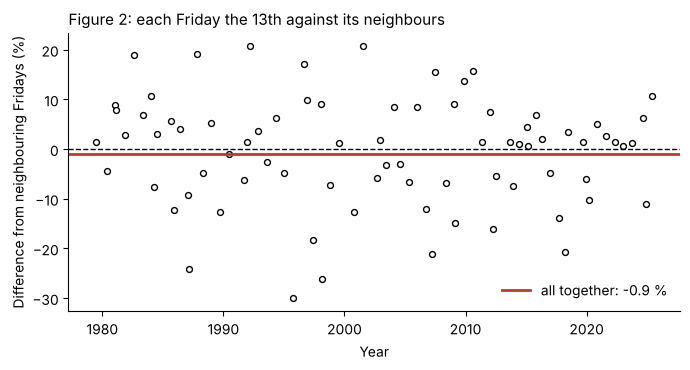

In [6]:
y = np.array([daily.loc[d, "all"] for d in main13], float)
c = np.array([daily.loc[[d.replace(day=k) for k in (6, 20) if d.replace(day=k) not in HOL], "all"].mean()
              for d in main13])
pct = 100 * (y / c - 1)
effect = 100 * (y.sum() / c.sum() - 1)
print(f"n = {len(y)}: 13ths {int(y.sum()):,}, comparison {c.sum():,.1f}, effect {effect:+.3f} %")
print(f"13th above its neighbours: {(pct > 0).sum()}, below: {(pct < 0).sum()}")
assert int(y.sum()) == M["sum13"] and (pct > 0).sum() == M["moreCount"] and (pct < 0).sum() == M["fewerCount"]
close(c.sum(), M["sumComparison"])
for d, v, p in zip(main13, pct, pub["points"]):
    assert d.isoformat() == p["date"]
    close(v, p["pct"], 0.006)
lo, hi = int(np.argmin(pct)), int(np.argmax(pct))
print(f"largest gaps: {main13[lo]} {pct[lo]:+.1f} %, {main13[hi]} {pct[hi]:+.1f} %")
ex = pub["example"]
d_ex = main13[-1]
assert d_ex.isoformat() == ex["date"]
assert [daily.loc[d_ex.replace(day=k), "all"] for k in (13, 6, 20)] == [ex["on13"], ex["on6"], ex["on20"]]
print(f"latest: {d_ex}: {ex['on13']} collisions; 6th {ex['on6']}, 20th {ex['on20']}")

years = [d.year + (d.month - 1) / 12 for d in main13]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.scatter(years, pct, facecolors="white", edgecolors="black", s=18)
ax.axhline(0, ls="--", color="black", lw=1)
ax.axhline(effect, color="#c0392b", lw=2, label=f"all together: {effect:+.1f} %")
ax.set_ylabel("Difference from neighbouring Fridays (%)")
ax.set_xlabel("Year")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Figure 2: each Friday the 13th against its neighbours", loc="left", fontsize=11)
plt.tight_layout()
plt.show()

### How uncertain is that?

Bootstrap over months: draw the months with replacement (each with its 13th and its comparison
days) 10,000 times and recompute the pooled effect. The 95% confidence interval runs from the
250th to the 9,751st replicate; the p-value counts the replicates on the far side of zero, so
p < 0.05 exactly when the interval excludes zero. Each calculation path has its own fixed random
stream, so the numbers match the published ones exactly. The next cell is
`notebooks/friday13_stats.py`.

In [7]:
# friday13_stats.py
# ──────────────────────────────────────────────────────────────────────
# Comparison days, the effect and the month bootstrap for story #005 (pitch 005, §1b). The
# pipeline and the notebook use the same procedure and the same random streams, so they produce
# identical numbers.
#
# For the months i with a Friday the 13th, y_i = collisions on the 13th and c_i = mean collisions
# per comparison day in the same month:
#
#     effect = 100 * (sum_i y_i / sum_i c_i - 1)        (per cent)
#
# A bootstrap draw resamples the months with replacement and is stored as count weights. The 95%
# confidence interval and p come from summarize(), the procedure of story #004 (moved here from
# coach_firing_stats.py when #004 was ported to R).
#
#   all_days:    every other day of the month
#   fridays:     the 6th and the 20th (the Fridays a week before and after)
#   friday_6th:  the 6th only (the design of Scanlon et al. 1993)
#
# With holidays excluded, a 13th that is a holiday drops out, holidays are removed from the
# comparison days, and a month without any comparison day left drops out.

import calendar
import datetime as dt
import zlib
from dataclasses import dataclass

import numpy as np
import pandas as pd

ALPHA = 0.05
COMPARISONS = ("all_days", "fridays", "friday_6th")


def fridays_13th(first_year: int, last_year: int) -> list[dt.date]:
    return [dt.date(y, m, 13) for y in range(first_year, last_year + 1) for m in range(1, 13)
            if dt.date(y, m, 13).weekday() == calendar.FRIDAY]


def comparison_days(day13: dt.date, comparison: str) -> list[dt.date]:
    if comparison == "all_days":
        last = calendar.monthrange(day13.year, day13.month)[1]
        return [day13.replace(day=d) for d in range(1, last + 1) if d != 13]
    if comparison == "fridays":
        return [day13.replace(day=6), day13.replace(day=20)]
    if comparison == "friday_6th":
        return [day13.replace(day=6)]
    raise ValueError(comparison)


@dataclass(frozen=True)
class Design:
    """Arrays for one calculation path."""

    dates: tuple[dt.date, ...]  # the Fridays the 13th that count
    y: np.ndarray  # (n,) collisions on the 13th
    c: np.ndarray  # (n,) mean collisions per comparison day, same month

    @property
    def n(self) -> int:
        return len(self.y)


def build_design(counts: pd.Series, comparison: str, holidays: set[dt.date] | None) -> Design:
    """counts: collisions per day, indexed by datetime.date, every day of the period present."""
    first, last = counts.index.min(), counts.index.max()
    dates, y, c = [], [], []
    for d13 in fridays_13th(first.year, last.year):
        if holidays is not None and d13 in holidays:
            continue
        days = [d for d in comparison_days(d13, comparison)
                if holidays is None or d not in holidays]
        if not days:
            continue
        dates.append(d13)
        y.append(counts[d13])
        c.append(np.mean([counts[d] for d in days]))
    return Design(tuple(dates), np.asarray(y, float), np.asarray(c, float))


def effects(design: Design, u: np.ndarray) -> np.ndarray:
    """Effect in per cent for month weights u (b, n)."""
    return 100 * ((u @ design.y) / (u @ design.c) - 1)


def point_estimate(design: Design) -> float:
    return float(effects(design, np.ones((1, design.n)))[0])


def bootstrap(design: Design, rng: np.random.Generator, b: int) -> np.ndarray:
    u = np.empty((b, design.n))
    for r in range(b):
        u[r] = np.bincount(rng.integers(0, design.n, design.n), minlength=design.n)
    return effects(design, u)


def summarize(reps: np.ndarray, alpha: float = ALPHA) -> dict[str, float]:
    """95% confidence interval from order statistics and the matching two-sided bootstrap p-value.

    With m = alpha/2 * B, the interval is the m-th to the (B + 1 - m)-th smallest replicate and
    p = 2 * min(#{<= 0}, #{>= 0}) / B. Then p < alpha exactly when the interval excludes 0.
    """
    b = len(reps)
    m = round(alpha / 2 * b)
    assert abs(alpha / 2 * b - m) < 1e-9, "alpha/2 * B must be a whole number"
    s = np.sort(reps)
    lo, hi = float(s[m - 1]), float(s[b - m])
    p = min(1.0, 2 * min(int((reps <= 0).sum()), int((reps >= 0).sum())) / b)
    assert (p < alpha) == (lo > 0 or hi < 0), (p, lo, hi)
    return {"ci_low": lo, "ci_high": hi, "p": p}


def path_rng(seed: int, key: str) -> np.random.Generator:
    """An independent random stream per calculation path, stable across runs and machines."""
    return np.random.default_rng([seed, zlib.crc32(key.encode("utf-8"))])


## 5. Every calculation path

Three choices decide the answer: what to compare with, which collisions to count, and what to do
with bank holidays. 3 × 3 × 2 = 18 paths. Each is recomputed here and must equal the published
table.

In [8]:
SEED, B = 5, 10_000
OPTIONS = {"comparison": ["all_days", "fridays", "friday_6th"], "outcome": ["all", "ksi", "fatal"],
           "holidays": ["exclude", "keep"]}
rows = []
for comparison in OPTIONS["comparison"]:
    for outcome in OPTIONS["outcome"]:
        for hol in OPTIONS["holidays"]:
            key = f"comparison={comparison}|outcome={outcome}|holidays={hol}"
            d = build_design(daily[outcome], comparison, HOL if hol == "exclude" else None)
            s = {"effect": point_estimate(d), **summarize(bootstrap(d, path_rng(SEED, key), B)), "n": d.n}
            rows.append({"comparison": comparison, "outcome": outcome, "holidays": hol, **s})
table = pd.DataFrame(rows)
print(table.round(3).to_string(index=False))
for r, p in zip(rows, pub["specs"]):
    assert {k: r[k] for k in ("comparison", "outcome", "holidays")} == p["choices"], (r, p["choices"])
    for k in ("effect", "ci_low", "ci_high", "p"):
        assert abs(r[k] - p[k]) < 1e-9, (k, r[k], p[k])
    assert r["n"] == p["n"]
main = table[(table.comparison == "fridays") & (table.outcome == "all") & (table.holidays == "exclude")].iloc[0]
close(main.effect, effect, 1e-9)
yes = ((table.p < 0.05) & (table.effect > 0)).sum()
print(f"main: {main.effect:+.2f} % [{main.ci_low:+.2f}, {main.ci_high:+.2f}], p = {main.p:.3f}; "
      f"upper bound below 5 %: {main.ci_high < 5}; yes on {yes} of {len(table)} paths")

comparison outcome holidays  effect  ci_low  ci_high     p  n
  all_days     all  exclude  19.365  16.663   22.018 0.000 78
  all_days     all     keep  19.294  16.284   22.258 0.000 81
  all_days     ksi  exclude  19.073  15.723   22.339 0.000 78
  all_days     ksi     keep  19.150  15.650   22.518 0.000 81
  all_days   fatal  exclude  18.200   8.398   27.780 0.000 78
  all_days   fatal     keep  18.888   9.247   28.453 0.000 81
   fridays     all  exclude  -0.883  -3.611    1.799 0.526 78
   fridays     all     keep  -0.915  -3.642    1.780 0.528 81
   fridays     ksi  exclude  -0.959  -4.161    2.326 0.563 78
   fridays     ksi     keep  -0.888  -4.024    2.304 0.581 81
   fridays   fatal  exclude   2.510  -6.440   11.995 0.587 78
   fridays   fatal     keep   2.696  -6.090   11.814 0.545 81
friday_6th     all  exclude  -0.095  -3.606    3.358 0.994 76
friday_6th     all     keep  -0.762  -4.357    2.809 0.683 81
friday_6th     ksi  exclude   0.281  -3.552    4.227 0.890 76
friday_6

## Data and methods

* **Source.** Department for Transport, Road Safety Data (STATS19), collisions 1979–2025:
  <https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-collision-1979-latest-published-year.csv>.
  Contains public sector information licensed under the Open Government Licence v3.0.
* **Coverage.** Every collision on a public road in Great Britain with at least one injured person
  that became known to the police. 8 records without a date are left out.
* **Definitions.** KSI = police severity fatal or serious; fatal = someone died within 30 days.
  From 2012 police forces moved to the CRASH system, which records more injuries as serious; this
  shifts the level, not the comparison within a month.
* **Main calculation.** Fridays the 13th that are not bank holidays against the mean of the 6th and
  the 20th of the same month; effect 100 · (Σ y / Σ c − 1); month bootstrap with B = 10,000.
* **Pre-registration.** Every fork, the effect formula, the bootstrap and the smallest relevant
  effect (+5 %) were fixed in the pitch before any comparison was computed (commit d260eb5).
* **Limitation.** Collisions per day, not risk per kilometre; the data have no daily traffic counts.

In [9]:
print("All statistics reproduced ✓")

All statistics reproduced ✓
